# 07 — Inventory Analysis

## Sales Order, Backlog & Inventory Analytics

### Objective

This notebook analyzes inventory position, stock availability, inventory value, allocation, and replenishment requirements across products and warehouses.

The analysis focuses on:

- Overall inventory KPIs
- On-hand, allocated, and available inventory
- Inventory value
- Stock status distribution
- Inventory days on hand
- Reorder requirements
- Safety stock and reorder point exposure
- Inventory allocation
- Inventory by product category
- Inventory by warehouse
- High-value inventory exposure
- Slow-moving and excess inventory indicators
- Product-level inventory risk

Backlog, shipment, supplier, and purchase order performance are analyzed separately in their respective notebooks.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Pandas version :", pd.__version__)
print("NumPy version  :", np.__version__)

print(
    "\nInventory Analysis environment initialized successfully."
)

Pandas version : 3.0.6
NumPy version  : 2.5.3

Inventory Analysis environment initialized successfully.


## Step 2 — Define Feature-Engineered Data Path

Define the project directory and the location of the feature-engineered datasets.

Inventory Analysis will use the analysis-ready datasets produced by `04_Feature_Engineering.ipynb`.

In [3]:
# Define project paths

project_path = Path.cwd().parent

featured_data_path = (
    project_path / "data" / "featured"
)

print("Project Path       :", project_path)
print("Featured Data Path :", featured_data_path)

print(
    "\nFeatured Data Folder Exists :",
    featured_data_path.exists()
)

Project Path       : c:\Users\Admin\OneDrive\Documents\Sales_Order_Backlog_Inventory_Analytics
Featured Data Path : c:\Users\Admin\OneDrive\Documents\Sales_Order_Backlog_Inventory_Analytics\data\featured

Featured Data Folder Exists : True


## Step 3 — Load Inventory Analysis Datasets

Load the feature-engineered datasets required for Inventory Analysis.

The analysis uses:

- Inventory
- Products
- Warehouses
- Inventory Transactions

These datasets provide the stock position, product attributes, warehouse information, and inventory movement data required for detailed inventory analysis.


In [4]:
# Load datasets required for Inventory Analysis

inventory = pd.read_csv(
    featured_data_path / "inventory_featured.csv"
)

products = pd.read_csv(
    featured_data_path / "products_featured.csv"
)

warehouses = pd.read_csv(
    featured_data_path / "warehouses_featured.csv"
)

inventory_transactions = pd.read_csv(
    featured_data_path / "inventory_transactions_featured.csv",
    parse_dates=["transaction_date"]
)


inventory_datasets = {
    "Inventory": inventory,
    "Products": products,
    "Warehouses": warehouses,
    "Inventory Transactions": inventory_transactions
}


print("Inventory Analysis datasets loaded successfully.\n")

for name, df in inventory_datasets.items():
    print(
        f"{name:<25} "
        f"{df.shape[0]:>7,} rows × "
        f"{df.shape[1]:>2} columns"
    )

Inventory Analysis datasets loaded successfully.

Inventory                   3,000 rows × 15 columns
Products                      500 rows × 10 columns
Warehouses                      6 rows ×  5 columns
Inventory Transactions    110,000 rows ×  6 columns


## Step 4 — Overall Inventory KPIs

Calculate the core inventory KPIs to understand the organization's current stock position.

Key metrics include:

- Total On-Hand Quantity
- Total Allocated Quantity
- Total Available Quantity
- Total Inventory Value
- Allocation Rate
- Number of Products
- Number of Warehouses
- Inventory Records Requiring Reorder
- Reorder Requirement Rate
- Average Inventory Days on Hand

In [5]:
# Overall Inventory KPIs

total_on_hand_qty = inventory["on_hand_qty"].sum()

total_allocated_qty = inventory["allocated_qty"].sum()

total_available_qty = inventory["available_qty"].sum()

total_inventory_value = inventory["inventory_value"].sum()


overall_allocation_rate = (
    total_allocated_qty
    / total_on_hand_qty
    * 100
)


unique_products = inventory["product_id"].nunique()

unique_warehouses = inventory["warehouse_id"].nunique()


reorder_records = (
    inventory["reorder_required_flag"]
    .eq("Y")
    .sum()
)

reorder_rate = (
    reorder_records
    / len(inventory)
    * 100
)


avg_inventory_days_on_hand = (
    inventory["inventory_days_on_hand"].mean()
)


print("OVERALL INVENTORY KPIs\n")

print(
    f"Total On-Hand Quantity          : "
    f"{total_on_hand_qty:,}"
)

print(
    f"Total Allocated Quantity        : "
    f"{total_allocated_qty:,}"
)

print(
    f"Total Available Quantity        : "
    f"{total_available_qty:,}"
)

print(
    f"Total Inventory Value           : "
    f"{total_inventory_value:,.2f}"
)

print(
    f"Overall Allocation Rate         : "
    f"{overall_allocation_rate:.2f}%"
)

print()

print(
    f"Unique Products                 : "
    f"{unique_products:,}"
)

print(
    f"Unique Warehouses               : "
    f"{unique_warehouses:,}"
)

print(
    f"Inventory Records               : "
    f"{len(inventory):,}"
)

print(
    f"Records Requiring Reorder       : "
    f"{reorder_records:,}"
)

print(
    f"Reorder Requirement Rate        : "
    f"{reorder_rate:.2f}%"
)

print(
    f"Average Inventory Days on Hand  : "
    f"{avg_inventory_days_on_hand:.2f} days"
)

OVERALL INVENTORY KPIs

Total On-Hand Quantity          : 85,305
Total Allocated Quantity        : 7,086
Total Available Quantity        : 78,219
Total Inventory Value           : 285,985,182.04
Overall Allocation Rate         : 8.31%

Unique Products                 : 500
Unique Warehouses               : 6
Inventory Records               : 3,000
Records Requiring Reorder       : 1,311
Reorder Requirement Rate        : 43.70%
Average Inventory Days on Hand  : 32.18 days


## Step 5 — Stock Status Distribution

Analyze the distribution of inventory records across stock status categories.

The analysis measures:

- Number of Inventory Records
- Total On-Hand Quantity
- Total Available Quantity
- Inventory Value
- Share of Inventory Records
- Share of Total Inventory Value

This provides an overall view of inventory health and identifies how much stock value is associated with each inventory status.

In [6]:
# Stock status distribution

stock_status_summary = (
    inventory
    .groupby("stock_status")
    .agg(
        inventory_records=("product_id", "count"),
        on_hand_qty=("on_hand_qty", "sum"),
        available_qty=("available_qty", "sum"),
        inventory_value=("inventory_value", "sum")
    )
    .reset_index()
)


stock_status_summary["record_share_pct"] = (
    stock_status_summary["inventory_records"]
    / len(inventory)
    * 100
)


stock_status_summary["inventory_value_share_pct"] = (
    stock_status_summary["inventory_value"]
    / total_inventory_value
    * 100
)


stock_status_summary = (
    stock_status_summary
    .sort_values(
        "inventory_value",
        ascending=False
    )
)


print("STOCK STATUS DISTRIBUTION\n")

print(
    stock_status_summary.to_string(
        index=False,
        formatters={
            "inventory_value":
                lambda x: f"{x:,.2f}",
            "record_share_pct":
                lambda x: f"{x:.2f}%",
            "inventory_value_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)


print(
    "\nInventory Records Classified :",
    f"{stock_status_summary['inventory_records'].sum():,}"
)

print(
    "Expected Inventory Records   :",
    f"{len(inventory):,}"
)

STOCK STATUS DISTRIBUTION

stock_status  inventory_records  on_hand_qty  available_qty inventory_value record_share_pct inventory_value_share_pct
     Healthy               2077        58143          52887  195,484,240.67           69.23%                    68.35%
   Overstock                478        25419          24330   84,770,923.88           15.93%                    29.64%
   Low Stock                205         1685           1002    5,522,621.31            6.83%                     1.93%
    Stockout                240           58              0      207,396.18            8.00%                     0.07%

Inventory Records Classified : 3,000
Expected Inventory Records   : 3,000


## Step 6 — Reorder Requirement Analysis

Analyze inventory records that have reached or fallen below their reorder point.

The analysis measures:

- Inventory Records
- On-Hand Quantity
- Available Quantity
- Inventory Value
- Share of Inventory Records
- Share of Inventory Value

This helps quantify the scale of inventory positions requiring replenishment attention.

In [7]:
# Reorder requirement analysis

reorder_summary = (
    inventory
    .groupby("reorder_required_flag")
    .agg(
        inventory_records=("product_id", "count"),
        on_hand_qty=("on_hand_qty", "sum"),
        available_qty=("available_qty", "sum"),
        inventory_value=("inventory_value", "sum")
    )
    .reset_index()
)


reorder_summary["record_share_pct"] = (
    reorder_summary["inventory_records"]
    / len(inventory)
    * 100
)


reorder_summary["inventory_value_share_pct"] = (
    reorder_summary["inventory_value"]
    / total_inventory_value
    * 100
)


print("REORDER REQUIREMENT ANALYSIS\n")

print(
    reorder_summary.to_string(
        index=False,
        formatters={
            "inventory_value":
                lambda x: f"{x:,.2f}",
            "record_share_pct":
                lambda x: f"{x:.2f}%",
            "inventory_value_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)


print(
    "\nRecords Requiring Reorder :",
    f"{reorder_records:,}"
)

print(
    "Reorder Requirement Rate  :",
    f"{reorder_rate:.2f}%"
)

REORDER REQUIREMENT ANALYSIS

reorder_required_flag  inventory_records  on_hand_qty  available_qty inventory_value record_share_pct inventory_value_share_pct
                    N               1689        69516          65295  234,506,268.15           56.30%                    82.00%
                    Y               1311        15789          12924   51,478,913.89           43.70%                    18.00%

Records Requiring Reorder : 1,311
Reorder Requirement Rate  : 43.70%


## Step 7 — Inventory Days on Hand Distribution

Analyze inventory coverage based on available quantity and average daily demand.

Inventory positions are grouped into coverage bands:

- 0 Days
- 1–7 Days
- 8–15 Days
- 16–30 Days
- 31–60 Days
- 61+ Days

This helps distinguish immediate stock risk from healthy inventory coverage and potential excess inventory.

In [8]:
# Create Inventory Days on Hand bands

inventory["days_on_hand_band"] = pd.cut(
    inventory["inventory_days_on_hand"],
    bins=[
        -0.01,
        0,
        7,
        15,
        30,
        60,
        np.inf
    ],
    labels=[
        "0 Days",
        "1-7 Days",
        "8-15 Days",
        "16-30 Days",
        "31-60 Days",
        "61+ Days"
    ]
)


# Summarize inventory coverage

days_on_hand_summary = (
    inventory
    .groupby(
        "days_on_hand_band",
        observed=True
    )
    .agg(
        inventory_records=("product_id", "count"),
        available_qty=("available_qty", "sum"),
        inventory_value=("inventory_value", "sum")
    )
    .reset_index()
)


days_on_hand_summary["record_share_pct"] = (
    days_on_hand_summary["inventory_records"]
    / len(inventory)
    * 100
)


days_on_hand_summary["inventory_value_share_pct"] = (
    days_on_hand_summary["inventory_value"]
    / total_inventory_value
    * 100
)


print("INVENTORY DAYS ON HAND DISTRIBUTION\n")

print(
    days_on_hand_summary.to_string(
        index=False,
        formatters={
            "inventory_value":
                lambda x: f"{x:,.2f}",
            "record_share_pct":
                lambda x: f"{x:.2f}%",
            "inventory_value_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)


print(
    "\nInventory Records Classified :",
    f"{days_on_hand_summary['inventory_records'].sum():,}"
)

print(
    "Expected Inventory Records   :",
    f"{len(inventory):,}"
)

INVENTORY DAYS ON HAND DISTRIBUTION

days_on_hand_band  inventory_records  available_qty inventory_value record_share_pct inventory_value_share_pct
           0 Days                240              0      207,396.18            8.00%                     0.07%
         1-7 Days                174            733    4,644,871.75            5.80%                     1.62%
        8-15 Days                327           3096   12,699,803.99           10.90%                     4.44%
       16-30 Days                692          12755   47,789,491.91           23.07%                    16.71%
       31-60 Days               1236          45117  161,574,464.99           41.20%                    56.50%
         61+ Days                331          16518   59,069,153.22           11.03%                    20.65%

Inventory Records Classified : 3,000
Expected Inventory Records   : 3,000


## Step 8 — Inventory Allocation Analysis

Analyze inventory allocation across product-warehouse positions.

The analysis measures:

- On-Hand Quantity
- Allocated Quantity
- Unallocated Quantity
- Allocation Rate

This helps evaluate how much current inventory is already committed to demand and how much remains unallocated.

In [9]:
# Inventory allocation analysis

allocation_summary = pd.DataFrame({
    "metric": [
        "On-Hand Quantity",
        "Allocated Quantity",
        "Unallocated Quantity"
    ],

    "quantity": [
        inventory["on_hand_qty"].sum(),
        inventory["allocated_qty"].sum(),
        inventory["unallocated_qty"].sum()
    ]
})


total_unallocated_qty = (
    inventory["unallocated_qty"].sum()
)


allocation_rate = (
    inventory["allocated_qty"].sum()
    / inventory["on_hand_qty"].sum()
    * 100
)


unallocated_rate = (
    total_unallocated_qty
    / inventory["on_hand_qty"].sum()
    * 100
)


print("INVENTORY ALLOCATION ANALYSIS\n")

print(
    allocation_summary.to_string(
        index=False
    )
)

print(
    f"\nAllocation Rate   : "
    f"{allocation_rate:.2f}%"
)

print(
    f"Unallocated Rate  : "
    f"{unallocated_rate:.2f}%"
)

print(
    "\nQuantity Reconciliation :",
    inventory["allocated_qty"].sum()
    + total_unallocated_qty
    == inventory["on_hand_qty"].sum()
)

INVENTORY ALLOCATION ANALYSIS

              metric  quantity
    On-Hand Quantity     85305
  Allocated Quantity      7086
Unallocated Quantity     78219

Allocation Rate   : 8.31%
Unallocated Rate  : 91.69%

Quantity Reconciliation : True


## Step 9 — Inventory by Product Category

Analyze inventory position across product categories.

The analysis measures:

- Inventory Records
- Unique Products
- On-Hand Quantity
- Available Quantity
- Inventory Value
- Share of Total Inventory Value
- Average Inventory Days on Hand
- Records Requiring Reorder

This helps identify categories with the greatest inventory investment and replenishment exposure.

In [10]:
# Merge product information into Inventory

inventory_product = inventory.merge(
    products[
        [
            "product_id",
            "product_name",
            "category",
            "subcategory"
        ]
    ],
    on="product_id",
    how="left"
)


print(
    "Missing Product Category After Merge :",
    inventory_product["category"].isna().sum()
)


# Inventory analysis by product category

category_inventory = (
    inventory_product
    .groupby("category")
    .agg(
        inventory_records=("product_id", "count"),
        unique_products=("product_id", "nunique"),
        on_hand_qty=("on_hand_qty", "sum"),
        available_qty=("available_qty", "sum"),
        inventory_value=("inventory_value", "sum"),
        avg_days_on_hand=(
            "inventory_days_on_hand",
            "mean"
        ),
        reorder_records=(
            "reorder_required_flag",
            lambda x: (x == "Y").sum()
        )
    )
    .reset_index()
)


category_inventory["inventory_value_share_pct"] = (
    category_inventory["inventory_value"]
    / total_inventory_value
    * 100
)


category_inventory["reorder_rate_pct"] = (
    category_inventory["reorder_records"]
    / category_inventory["inventory_records"]
    * 100
)


category_inventory = category_inventory.sort_values(
    "inventory_value",
    ascending=False
)


print("\nINVENTORY BY PRODUCT CATEGORY\n")

print(
    category_inventory.to_string(
        index=False,
        formatters={
            "inventory_value":
                lambda x: f"{x:,.2f}",
            "avg_days_on_hand":
                lambda x: f"{x:.2f}",
            "inventory_value_share_pct":
                lambda x: f"{x:.2f}%",
            "reorder_rate_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)

Missing Product Category After Merge : 0

INVENTORY BY PRODUCT CATEGORY

              category  inventory_records  unique_products  on_hand_qty  available_qty inventory_value avg_days_on_hand  reorder_records inventory_value_share_pct reorder_rate_pct
           Electronics                732              122        22291          20347   79,180,029.99            31.78              313                    27.69%           42.76%
       Office Supplies                582               97        16165          14822   55,462,605.80            31.83              258                    19.39%           44.33%
        Home & Kitchen                654              109        16785          15409   53,950,557.42            33.57              269                    18.86%           41.13%
Health & Personal Care                576               96        15539          14273   50,175,615.88            31.72              271                    17.54%           47.05%
            Automotive     

## Step 10 — Inventory by Warehouse

Analyze inventory position across warehouses.

The analysis measures:

- Inventory Records
- Unique Products
- On-Hand Quantity
- Allocated Quantity
- Available Quantity
- Inventory Value
- Share of Total Inventory Value
- Average Inventory Days on Hand
- Records Requiring Reorder
- Reorder Rate

This helps identify warehouses with the greatest inventory investment and replenishment exposure.

In [11]:
# Merge warehouse information into Inventory

inventory_warehouse = inventory.merge(
    warehouses[
        [
            "warehouse_id",
            "warehouse_name",
            "city",
            "region"
        ]
    ],
    on="warehouse_id",
    how="left"
)


print(
    "Missing Warehouse Name After Merge :",
    inventory_warehouse["warehouse_name"].isna().sum()
)


# Inventory analysis by warehouse

warehouse_inventory = (
    inventory_warehouse
    .groupby(
        [
            "warehouse_id",
            "warehouse_name"
        ]
    )
    .agg(
        inventory_records=("product_id", "count"),
        unique_products=("product_id", "nunique"),
        on_hand_qty=("on_hand_qty", "sum"),
        allocated_qty=("allocated_qty", "sum"),
        available_qty=("available_qty", "sum"),
        inventory_value=("inventory_value", "sum"),
        avg_days_on_hand=(
            "inventory_days_on_hand",
            "mean"
        ),
        reorder_records=(
            "reorder_required_flag",
            lambda x: (x == "Y").sum()
        )
    )
    .reset_index()
)


warehouse_inventory["inventory_value_share_pct"] = (
    warehouse_inventory["inventory_value"]
    / total_inventory_value
    * 100
)


warehouse_inventory["reorder_rate_pct"] = (
    warehouse_inventory["reorder_records"]
    / warehouse_inventory["inventory_records"]
    * 100
)


warehouse_inventory = warehouse_inventory.sort_values(
    "inventory_value",
    ascending=False
)


print("\nINVENTORY BY WAREHOUSE\n")

print(
    warehouse_inventory.to_string(
        index=False,
        formatters={
            "inventory_value":
                lambda x: f"{x:,.2f}",
            "avg_days_on_hand":
                lambda x: f"{x:.2f}",
            "inventory_value_share_pct":
                lambda x: f"{x:.2f}%",
            "reorder_rate_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)

Missing Warehouse Name After Merge : 0

INVENTORY BY WAREHOUSE

warehouse_id    warehouse_name  inventory_records  unique_products  on_hand_qty  allocated_qty  available_qty inventory_value avg_days_on_hand  reorder_records inventory_value_share_pct reorder_rate_pct
        WH05       Chennai Hub                500              500        15121           1177          13944   51,086,797.70            33.49              212                    17.86%           42.40%
        WH01 Bengaluru Central                500              500        14433           1173          13260   48,514,594.37            31.74              234                    16.96%           46.80%
        WH02       Mumbai West                500              500        14356           1194          13162   47,404,063.86            32.47              212                    16.58%           42.40%
        WH04   Hyderabad South                500              500        13952           1164          12788   47,126,003.3

## Step 11 — Stockout Analysis

Analyze product-warehouse inventory positions currently classified as Stockout.

The analysis measures:

- Number of Stockout Records
- Unique Products Affected
- Warehouses Affected
- On-Hand Quantity
- Allocated Quantity
- Available Quantity
- Inventory Value
- Average Daily Demand

This helps quantify the immediate inventory availability risk across the network.

In [12]:
# Filter stockout inventory positions

stockout_inventory = inventory_product[
    inventory_product["stock_status"] == "Stockout"
].copy()


stockout_records = len(stockout_inventory)

stockout_products = (
    stockout_inventory["product_id"].nunique()
)

stockout_warehouses = (
    stockout_inventory["warehouse_id"].nunique()
)

stockout_on_hand = (
    stockout_inventory["on_hand_qty"].sum()
)

stockout_allocated = (
    stockout_inventory["allocated_qty"].sum()
)

stockout_available = (
    stockout_inventory["available_qty"].sum()
)

stockout_inventory_value = (
    stockout_inventory["inventory_value"].sum()
)

stockout_daily_demand = (
    stockout_inventory["avg_daily_demand"].sum()
)


print("STOCKOUT ANALYSIS\n")

print(
    f"Stockout Records          : "
    f"{stockout_records:,}"
)

print(
    f"Unique Products Affected  : "
    f"{stockout_products:,}"
)

print(
    f"Warehouses Affected       : "
    f"{stockout_warehouses:,}"
)

print()

print(
    f"On-Hand Quantity          : "
    f"{stockout_on_hand:,}"
)

print(
    f"Allocated Quantity        : "
    f"{stockout_allocated:,}"
)

print(
    f"Available Quantity        : "
    f"{stockout_available:,}"
)

print(
    f"Inventory Value           : "
    f"{stockout_inventory_value:,.2f}"
)

print(
    f"Combined Avg Daily Demand : "
    f"{stockout_daily_demand:,.2f}"
)

STOCKOUT ANALYSIS

Stockout Records          : 240
Unique Products Affected  : 198
Warehouses Affected       : 6

On-Hand Quantity          : 58
Allocated Quantity        : 58
Available Quantity        : 0
Inventory Value           : 207,396.18
Combined Avg Daily Demand : 193.87


## Step 12 — Stockouts by Warehouse

Analyze stockout exposure across warehouses.

The analysis measures:

- Stockout Records
- Unique Products Stocked Out
- Combined Average Daily Demand
- Share of Total Stockout Records

This helps identify warehouses experiencing the greatest immediate inventory availability risk.

In [13]:
# Add warehouse information to stockout records

stockout_warehouse = stockout_inventory.merge(
    warehouses[
        [
            "warehouse_id",
            "warehouse_name"
        ]
    ],
    on="warehouse_id",
    how="left"
)


print(
    "Missing Warehouse Name After Merge :",
    stockout_warehouse["warehouse_name"].isna().sum()
)


# Stockouts by warehouse

warehouse_stockouts = (
    stockout_warehouse
    .groupby(
        [
            "warehouse_id",
            "warehouse_name"
        ]
    )
    .agg(
        stockout_records=("product_id", "count"),
        unique_products=("product_id", "nunique"),
        avg_daily_demand=("avg_daily_demand", "sum")
    )
    .reset_index()
)


warehouse_stockouts["stockout_share_pct"] = (
    warehouse_stockouts["stockout_records"]
    / stockout_records
    * 100
)


warehouse_stockouts = warehouse_stockouts.sort_values(
    "stockout_records",
    ascending=False
)


print("\nSTOCKOUTS BY WAREHOUSE\n")

print(
    warehouse_stockouts.to_string(
        index=False,
        formatters={
            "avg_daily_demand":
                lambda x: f"{x:.2f}",
            "stockout_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)

Missing Warehouse Name After Merge : 0

STOCKOUTS BY WAREHOUSE

warehouse_id    warehouse_name  stockout_records  unique_products avg_daily_demand stockout_share_pct
        WH04   Hyderabad South                50               50            43.52             20.83%
        WH06           Pune DC                42               42            30.62             17.50%
        WH05       Chennai Hub                40               40            32.19             16.67%
        WH02       Mumbai West                38               38            29.11             15.83%
        WH03         Delhi NCR                36               36            31.33             15.00%
        WH01 Bengaluru Central                34               34            27.10             14.17%


## Step 13 — Stockouts by Product Category

Analyze stockout exposure across product categories.

The analysis measures:

- Inventory Records
- Stockout Records
- Stockout Rate
- Unique Products Stocked Out
- Combined Average Daily Demand
- Share of Total Stockout Records

This helps identify product categories experiencing the greatest immediate availability risk.

In [14]:
# Stockout analysis by product category

category_stockouts = (
    inventory_product
    .groupby("category")
    .agg(
        inventory_records=("product_id", "count"),

        stockout_records=(
            "stock_status",
            lambda x: (x == "Stockout").sum()
        ),

        unique_stockout_products=(
            "product_id",
            lambda x: x[
                inventory_product.loc[
                    x.index,
                    "stock_status"
                ] == "Stockout"
            ].nunique()
        ),

        stockout_daily_demand=(
            "avg_daily_demand",
            lambda x: x[
                inventory_product.loc[
                    x.index,
                    "stock_status"
                ] == "Stockout"
            ].sum()
        )
    )
    .reset_index()
)


category_stockouts["stockout_rate_pct"] = (
    category_stockouts["stockout_records"]
    / category_stockouts["inventory_records"]
    * 100
)


category_stockouts["stockout_share_pct"] = (
    category_stockouts["stockout_records"]
    / stockout_records
    * 100
)


category_stockouts = category_stockouts.sort_values(
    "stockout_records",
    ascending=False
)


print("STOCKOUTS BY PRODUCT CATEGORY\n")

print(
    category_stockouts.to_string(
        index=False,
        formatters={
            "stockout_rate_pct":
                lambda x: f"{x:.2f}%",

            "stockout_daily_demand":
                lambda x: f"{x:.2f}",

            "stockout_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)


print(
    "\nStockout Records Reconciled :",
    category_stockouts["stockout_records"].sum()
)

print(
    "Expected Stockout Records   :",
    stockout_records
)

STOCKOUTS BY PRODUCT CATEGORY

              category  inventory_records  stockout_records  unique_stockout_products stockout_daily_demand stockout_rate_pct stockout_share_pct
        Home & Kitchen                654                52                        44                 31.64             7.95%             21.67%
           Electronics                732                48                        42                 45.36             6.56%             20.00%
            Automotive                456                47                        39                 52.59            10.31%             19.58%
Health & Personal Care                576                47                        38                 36.93             8.16%             19.58%
       Office Supplies                582                46                        35                 27.35             7.90%             19.17%

Stockout Records Reconciled : 240
Expected Stockout Records   : 240


## Step 14 — Overstock Analysis

Analyze product-warehouse inventory positions classified as Overstock.

The analysis measures:

- Overstock Records
- Unique Products Affected
- Warehouses Affected
- On-Hand Quantity
- Available Quantity
- Inventory Value
- Share of Total Inventory Value
- Average Inventory Days on Hand

This helps quantify excess inventory exposure and the amount of working capital tied up in high-stock positions.

In [15]:
# Filter overstock inventory positions

overstock_inventory = inventory_product[
    inventory_product["stock_status"] == "Overstock"
].copy()


overstock_records = len(overstock_inventory)

overstock_products = (
    overstock_inventory["product_id"].nunique()
)

overstock_warehouses = (
    overstock_inventory["warehouse_id"].nunique()
)

overstock_on_hand = (
    overstock_inventory["on_hand_qty"].sum()
)

overstock_available = (
    overstock_inventory["available_qty"].sum()
)

overstock_value = (
    overstock_inventory["inventory_value"].sum()
)

overstock_value_share = (
    overstock_value
    / total_inventory_value
    * 100
)

overstock_avg_days = (
    overstock_inventory[
        "inventory_days_on_hand"
    ].mean()
)


print("OVERSTOCK ANALYSIS\n")

print(
    f"Overstock Records               : "
    f"{overstock_records:,}"
)

print(
    f"Unique Products Affected        : "
    f"{overstock_products:,}"
)

print(
    f"Warehouses Affected             : "
    f"{overstock_warehouses:,}"
)

print()

print(
    f"On-Hand Quantity                : "
    f"{overstock_on_hand:,}"
)

print(
    f"Available Quantity              : "
    f"{overstock_available:,}"
)

print(
    f"Overstock Inventory Value       : "
    f"{overstock_value:,.2f}"
)

print(
    f"Share of Total Inventory Value  : "
    f"{overstock_value_share:.2f}%"
)

print(
    f"Average Inventory Days on Hand  : "
    f"{overstock_avg_days:.2f} days"
)

OVERSTOCK ANALYSIS

Overstock Records               : 478
Unique Products Affected        : 320
Warehouses Affected             : 6

On-Hand Quantity                : 25,419
Available Quantity              : 24,330
Overstock Inventory Value       : 84,770,923.88
Share of Total Inventory Value  : 29.64%
Average Inventory Days on Hand  : 60.74 days


## Step 15 — Overstock by Product Category

Analyze excess inventory exposure across product categories.

The analysis measures:

- Overstock Records
- Unique Products Affected
- Overstock On-Hand Quantity
- Overstock Available Quantity
- Overstock Inventory Value
- Share of Total Overstock Value
- Average Inventory Days on Hand

This helps identify the product categories where excess inventory and working-capital exposure are concentrated.

In [16]:
# Overstock analysis by product category

category_overstock = (
    overstock_inventory
    .groupby("category")
    .agg(
        overstock_records=("product_id", "count"),
        unique_products=("product_id", "nunique"),
        on_hand_qty=("on_hand_qty", "sum"),
        available_qty=("available_qty", "sum"),
        overstock_value=("inventory_value", "sum"),
        avg_days_on_hand=(
            "inventory_days_on_hand",
            "mean"
        )
    )
    .reset_index()
)


category_overstock["overstock_value_share_pct"] = (
    category_overstock["overstock_value"]
    / overstock_value
    * 100
)


category_overstock = category_overstock.sort_values(
    "overstock_value",
    ascending=False
)


print("OVERSTOCK BY PRODUCT CATEGORY\n")

print(
    category_overstock.to_string(
        index=False,
        formatters={
            "overstock_value":
                lambda x: f"{x:,.2f}",

            "avg_days_on_hand":
                lambda x: f"{x:.2f}",

            "overstock_value_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)


print(
    "\nOverstock Records Reconciled :",
    category_overstock["overstock_records"].sum()
)

print(
    "Expected Overstock Records   :",
    overstock_records
)

print(
    "Overstock Value Reconciled   :",
    f"{category_overstock['overstock_value'].sum():,.2f}"
)

print(
    "Expected Overstock Value     :",
    f"{overstock_value:,.2f}"
)

OVERSTOCK BY PRODUCT CATEGORY

              category  overstock_records  unique_products  on_hand_qty  available_qty overstock_value avg_days_on_hand overstock_value_share_pct
           Electronics                123               85         6999           6670   24,735,346.75            59.29                    29.18%
       Office Supplies                 91               59         4921           4706   17,441,325.36            61.72                    20.57%
        Home & Kitchen                113               69         5251           5033   16,068,691.72            60.03                    18.96%
            Automotive                 70               46         3883           3735   13,698,143.09            60.48                    16.16%
Health & Personal Care                 81               61         4365           4186   12,827,416.96            63.03                    15.13%

Overstock Records Reconciled : 478
Expected Overstock Records   : 478
Overstock Value Reconc

## Step 16 — Overstock by Warehouse

Analyze excess inventory exposure across warehouses.

The analysis measures:

- Overstock Records
- Unique Products Affected
- Overstock On-Hand Quantity
- Overstock Available Quantity
- Overstock Inventory Value
- Share of Total Overstock Value
- Average Inventory Days on Hand

This helps identify warehouses where excess inventory and working capital are most concentrated.

In [17]:
# Add warehouse information to overstock inventory

overstock_warehouse = overstock_inventory.merge(
    warehouses[
        [
            "warehouse_id",
            "warehouse_name"
        ]
    ],
    on="warehouse_id",
    how="left"
)


print(
    "Missing Warehouse Name After Merge :",
    overstock_warehouse["warehouse_name"].isna().sum()
)


# Overstock analysis by warehouse

warehouse_overstock = (
    overstock_warehouse
    .groupby(
        [
            "warehouse_id",
            "warehouse_name"
        ]
    )
    .agg(
        overstock_records=("product_id", "count"),
        unique_products=("product_id", "nunique"),
        on_hand_qty=("on_hand_qty", "sum"),
        available_qty=("available_qty", "sum"),
        overstock_value=("inventory_value", "sum"),
        avg_days_on_hand=(
            "inventory_days_on_hand",
            "mean"
        )
    )
    .reset_index()
)


warehouse_overstock["overstock_value_share_pct"] = (
    warehouse_overstock["overstock_value"]
    / overstock_value
    * 100
)


warehouse_overstock = warehouse_overstock.sort_values(
    "overstock_value",
    ascending=False
)


print("\nOVERSTOCK BY WAREHOUSE\n")

print(
    warehouse_overstock.to_string(
        index=False,
        formatters={
            "overstock_value":
                lambda x: f"{x:,.2f}",

            "avg_days_on_hand":
                lambda x: f"{x:.2f}",

            "overstock_value_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)


print(
    "\nOverstock Records Reconciled :",
    warehouse_overstock["overstock_records"].sum()
)

print(
    "Expected Overstock Records   :",
    overstock_records
)

print(
    "Overstock Value Reconciled   :",
    f"{warehouse_overstock['overstock_value'].sum():,.2f}"
)

print(
    "Expected Overstock Value     :",
    f"{overstock_value:,.2f}"
)

Missing Warehouse Name After Merge : 0

OVERSTOCK BY WAREHOUSE

warehouse_id    warehouse_name  overstock_records  unique_products  on_hand_qty  available_qty overstock_value avg_days_on_hand overstock_value_share_pct
        WH06           Pune DC                 90               90         4539           4338   16,050,532.78            60.48                    18.93%
        WH05       Chennai Hub                 90               90         4997           4777   15,341,760.84            61.04                    18.10%
        WH04   Hyderabad South                 72               72         3950           3789   14,504,612.61            61.58                    17.11%
        WH01 Bengaluru Central                 77               77         4367           4205   14,250,106.25            62.01                    16.81%
        WH03         Delhi NCR                 81               81         3985           3784   12,960,569.07            59.42                    15.29%
        WH02

## Step 17 — Top 10 Products by Inventory Value

Identify products with the highest total inventory value across the warehouse network.

The analysis measures:

- Product ID
- Product Name
- Product Category
- Total On-Hand Quantity
- Total Available Quantity
- Total Inventory Value
- Share of Total Inventory Value
- Average Inventory Days on Hand

This helps identify products representing the largest inventory investment and working-capital exposure.

In [18]:
# Product-level inventory analysis

product_inventory = (
    inventory_product
    .groupby(
        [
            "product_id",
            "product_name",
            "category"
        ]
    )
    .agg(
        on_hand_qty=("on_hand_qty", "sum"),
        available_qty=("available_qty", "sum"),
        inventory_value=("inventory_value", "sum"),
        avg_days_on_hand=(
            "inventory_days_on_hand",
            "mean"
        )
    )
    .reset_index()
)


product_inventory["inventory_value_share_pct"] = (
    product_inventory["inventory_value"]
    / total_inventory_value
    * 100
)


product_inventory = product_inventory.sort_values(
    "inventory_value",
    ascending=False
)


top_10_inventory_products = (
    product_inventory.head(10).copy()
)


top_10_inventory_value = (
    top_10_inventory_products[
        "inventory_value"
    ].sum()
)


top_10_inventory_share = (
    top_10_inventory_value
    / total_inventory_value
    * 100
)


print("TOP 10 PRODUCTS BY INVENTORY VALUE\n")

print(
    top_10_inventory_products.to_string(
        index=False,
        formatters={
            "inventory_value":
                lambda x: f"{x:,.2f}",

            "avg_days_on_hand":
                lambda x: f"{x:.2f}",

            "inventory_value_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)


print(
    "\nTop 10 Product Inventory Value :",
    f"{top_10_inventory_value:,.2f}"
)

print(
    "Top 10 Share of Total Inventory :",
    f"{top_10_inventory_share:.2f}%"
)

TOP 10 PRODUCTS BY INVENTORY VALUE

product_id               product_name               category  on_hand_qty  available_qty inventory_value avg_days_on_hand inventory_value_share_pct
   SKU0228 Smart Devices Product 0228            Electronics          943            853    6,098,107.53            34.01                     2.13%
   SKU0029   Maintenance Product 0029             Automotive          968            913    5,460,149.20            39.83                     1.91%
   SKU0157      Grooming Product 0157 Health & Personal Care          862            815    5,405,843.36            36.42                     1.89%
   SKU0006   Accessories Product 0006             Automotive          574            536    3,187,014.46            35.31                     1.11%
   SKU0145     Furniture Product 0145        Office Supplies          579            544    3,149,076.78            51.22                     1.10%
   SKU0217     Furniture Product 0217        Office Supplies         1017   

## Step 18 — High Inventory Days-on-Hand Products

Identify products with the highest average inventory days on hand across the warehouse network.

The analysis focuses on:

- Product ID
- Product Name
- Product Category
- On-Hand Quantity
- Available Quantity
- Inventory Value
- Average Inventory Days on Hand

Products with unusually high inventory coverage may indicate slow-moving stock, excess inventory, or opportunities to reduce working-capital exposure.

In [19]:
# Top products by average inventory days on hand

high_days_products = (
    product_inventory
    .sort_values(
        "avg_days_on_hand",
        ascending=False
    )
    .head(10)
    .copy()
)


print("TOP 10 PRODUCTS BY AVERAGE INVENTORY DAYS ON HAND\n")

print(
    high_days_products[
        [
            "product_id",
            "product_name",
            "category",
            "on_hand_qty",
            "available_qty",
            "inventory_value",
            "avg_days_on_hand"
        ]
    ].to_string(
        index=False,
        formatters={
            "inventory_value":
                lambda x: f"{x:,.2f}",

            "avg_days_on_hand":
                lambda x: f"{x:.2f}"
        }
    )
)

TOP 10 PRODUCTS BY AVERAGE INVENTORY DAYS ON HAND

product_id               product_name               category  on_hand_qty  available_qty inventory_value avg_days_on_hand
   SKU0277    Stationery Product 0277        Office Supplies          142            137      337,437.44            58.55
   SKU0055 Smart Devices Product 0055            Electronics           50             46      269,399.50            54.76
   SKU0022      Cookware Product 0022         Home & Kitchen          221            208      557,870.30            52.53
   SKU0103      Wellness Product 0103 Health & Personal Care          125            119      238,228.75            52.19
   SKU0405      Grooming Product 0405 Health & Personal Care           36             34      221,010.84            51.52
   SKU0145     Furniture Product 0145        Office Supplies          579            544    3,149,076.78            51.22
   SKU0357   Maintenance Product 0357             Automotive          308            289    1,9

## Step 19 — Inventory Risk Matrix

Create a consolidated inventory risk summary using the existing stock status classification.

The analysis compares:

- Inventory Records
- Available Quantity
- Inventory Value
- Share of Total Inventory Value
- Average Inventory Days on Hand
- Reorder Requirement Rate

This provides a management-level view of inventory availability risk and excess-stock exposure.

In [20]:
# Inventory risk matrix

inventory_risk_matrix = (
    inventory
    .groupby("stock_status")
    .agg(
        inventory_records=("product_id", "count"),
        available_qty=("available_qty", "sum"),
        inventory_value=("inventory_value", "sum"),
        avg_days_on_hand=(
            "inventory_days_on_hand",
            "mean"
        ),
        reorder_records=(
            "reorder_required_flag",
            lambda x: (x == "Y").sum()
        )
    )
    .reset_index()
)


inventory_risk_matrix["inventory_value_share_pct"] = (
    inventory_risk_matrix["inventory_value"]
    / total_inventory_value
    * 100
)


inventory_risk_matrix["reorder_rate_pct"] = (
    inventory_risk_matrix["reorder_records"]
    / inventory_risk_matrix["inventory_records"]
    * 100
)


status_order = [
    "Stockout",
    "Low Stock",
    "Healthy",
    "Overstock"
]


inventory_risk_matrix["stock_status"] = pd.Categorical(
    inventory_risk_matrix["stock_status"],
    categories=status_order,
    ordered=True
)


inventory_risk_matrix = (
    inventory_risk_matrix
    .sort_values("stock_status")
    .reset_index(drop=True)
)


print("INVENTORY RISK MATRIX\n")

print(
    inventory_risk_matrix.to_string(
        index=False,
        formatters={
            "inventory_value":
                lambda x: f"{x:,.2f}",

            "avg_days_on_hand":
                lambda x: f"{x:.2f}",

            "inventory_value_share_pct":
                lambda x: f"{x:.2f}%",

            "reorder_rate_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)

INVENTORY RISK MATRIX

stock_status  inventory_records  available_qty inventory_value avg_days_on_hand  reorder_records inventory_value_share_pct reorder_rate_pct
    Stockout                240              0      207,396.18             0.00              240                     0.07%          100.00%
   Low Stock                205           1002    5,522,621.31             5.61              205                     1.93%          100.00%
     Healthy               2077          52887  195,484,240.67            31.95              866                    68.35%           41.69%
   Overstock                478          24330   84,770,923.88            60.74                0                    29.64%            0.00%


## Step 20 — Inventory Value by Stock Status

Visualize inventory value across Stockout, Low Stock, Healthy, and Overstock positions.

This highlights the financial concentration of inventory across different stock conditions and makes excess inventory exposure easier to communicate.

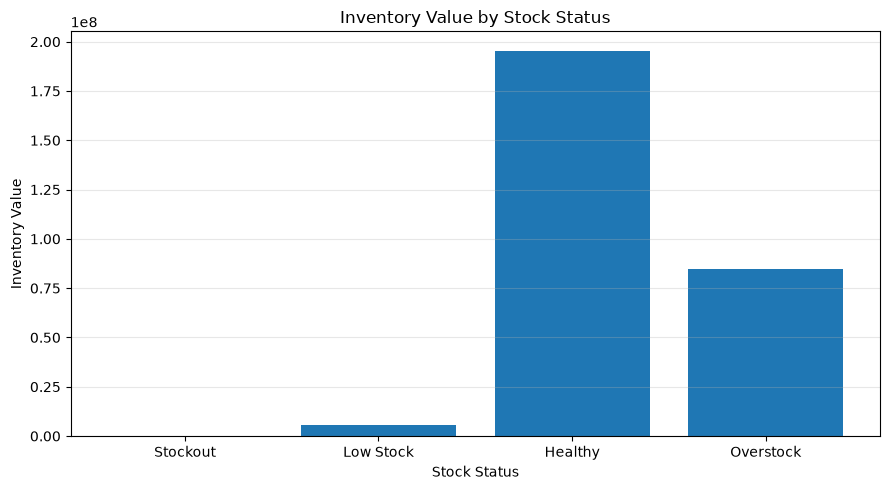

In [21]:
# Inventory Value by Stock Status

plt.figure(figsize=(9, 5))

plt.bar(
    inventory_risk_matrix["stock_status"].astype(str),
    inventory_risk_matrix["inventory_value"]
)

plt.title("Inventory Value by Stock Status")

plt.xlabel("Stock Status")
plt.ylabel("Inventory Value")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()

## Step 21 — Inventory Value by Product Category

Visualize total inventory value across product categories.

This highlights which product groups consume the greatest amount of inventory working capital and supports category-level inventory management decisions.

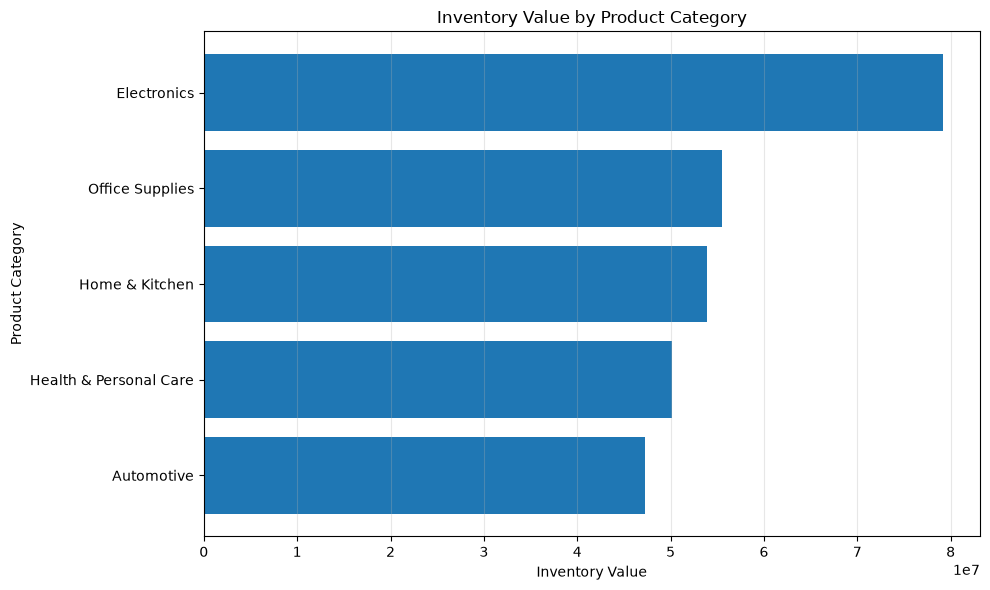

In [23]:
# Inventory Value by Product Category

category_plot = category_inventory.sort_values(
    "inventory_value",
    ascending=True
)


plt.figure(figsize=(10, 6))

plt.barh(
    category_plot["category"],
    category_plot["inventory_value"]
)

plt.title("Inventory Value by Product Category")

plt.xlabel("Inventory Value")
plt.ylabel("Product Category")

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

plt.show()

## Step 22 — Inventory Risk Areas Summary

Summarize the major inventory risk areas identified across stock status, product category, warehouse, stockout, overstock, and product-level analyses.

This provides a concise management-level view of inventory availability risk and excess working-capital exposure.

In [24]:
# Identify major inventory risk areas

highest_value_category = category_inventory.loc[
    category_inventory["inventory_value"].idxmax()
]

highest_reorder_category = category_inventory.loc[
    category_inventory["reorder_rate_pct"].idxmax()
]

highest_value_warehouse = warehouse_inventory.loc[
    warehouse_inventory["inventory_value"].idxmax()
]

highest_reorder_warehouse = warehouse_inventory.loc[
    warehouse_inventory["reorder_rate_pct"].idxmax()
]

highest_stockout_warehouse = warehouse_stockouts.loc[
    warehouse_stockouts["stockout_records"].idxmax()
]

highest_stockout_category = category_stockouts.loc[
    category_stockouts["stockout_rate_pct"].idxmax()
]

highest_overstock_category = category_overstock.loc[
    category_overstock["overstock_value"].idxmax()
]

highest_overstock_warehouse = warehouse_overstock.loc[
    warehouse_overstock["overstock_value"].idxmax()
]

highest_value_product = product_inventory.loc[
    product_inventory["inventory_value"].idxmax()
]

highest_days_product = product_inventory.loc[
    product_inventory["avg_days_on_hand"].idxmax()
]


print("INVENTORY RISK AREAS SUMMARY\n")

print(
    f"Highest Inventory Value Category : "
    f"{highest_value_category['category']} "
    f"({highest_value_category['inventory_value']:,.2f})"
)

print(
    f"Highest Category Reorder Rate    : "
    f"{highest_reorder_category['category']} "
    f"({highest_reorder_category['reorder_rate_pct']:.2f}%)"
)

print(
    f"Highest Inventory Value Warehouse: "
    f"{highest_value_warehouse['warehouse_name']} "
    f"({highest_value_warehouse['inventory_value']:,.2f})"
)

print(
    f"Highest Warehouse Reorder Rate   : "
    f"{highest_reorder_warehouse['warehouse_name']} "
    f"({highest_reorder_warehouse['reorder_rate_pct']:.2f}%)"
)

print(
    f"Highest Stockout Warehouse       : "
    f"{highest_stockout_warehouse['warehouse_name']} "
    f"({highest_stockout_warehouse['stockout_records']:,} records)"
)

print(
    f"Highest Category Stockout Rate   : "
    f"{highest_stockout_category['category']} "
    f"({highest_stockout_category['stockout_rate_pct']:.2f}%)"
)

print(
    f"Highest Overstock Value Category : "
    f"{highest_overstock_category['category']} "
    f"({highest_overstock_category['overstock_value']:,.2f})"
)

print(
    f"Highest Overstock Value Warehouse: "
    f"{highest_overstock_warehouse['warehouse_name']} "
    f"({highest_overstock_warehouse['overstock_value']:,.2f})"
)

print(
    f"Highest Value Product            : "
    f"{highest_value_product['product_name']} "
    f"({highest_value_product['inventory_value']:,.2f})"
)

print(
    f"Highest Avg Days-on-Hand Product : "
    f"{highest_days_product['product_name']} "
    f"({highest_days_product['avg_days_on_hand']:.2f} days)"
)

INVENTORY RISK AREAS SUMMARY

Highest Inventory Value Category : Electronics (79,180,029.99)
Highest Category Reorder Rate    : Health & Personal Care (47.05%)
Highest Inventory Value Warehouse: Chennai Hub (51,086,797.70)
Highest Warehouse Reorder Rate   : Pune DC (48.20%)
Highest Stockout Warehouse       : Hyderabad South (50 records)
Highest Category Stockout Rate   : Automotive (10.31%)
Highest Overstock Value Category : Electronics (24,735,346.75)
Highest Overstock Value Warehouse: Pune DC (16,050,532.78)
Highest Value Product            : Smart Devices Product 0228 (6,098,107.53)
Highest Avg Days-on-Hand Product : Stationery Product 0277 (58.55 days)


## Step 23 — Inventory Reconciliation

Validate the core inventory quantities, stock-status classifications, reorder classifications, and inventory values used throughout the analysis.

This ensures that the Inventory Analysis remains internally consistent before final conclusions are documented.

In [25]:
# Inventory reconciliation

on_hand_reconciliation = (
    inventory["allocated_qty"].sum()
    + inventory["available_qty"].sum()
)

stock_status_records = (
    stock_status_summary["inventory_records"].sum()
)

stock_status_value = (
    stock_status_summary["inventory_value"].sum()
)

reorder_summary_records = (
    reorder_summary["inventory_records"].sum()
)

reorder_summary_value = (
    reorder_summary["inventory_value"].sum()
)


print("INVENTORY RECONCILIATION\n")

print(
    f"Total On-Hand Quantity        : "
    f"{total_on_hand_qty:,}"
)

print(
    f"Allocated + Available         : "
    f"{on_hand_reconciliation:,}"
)

print(
    f"Quantity Difference           : "
    f"{total_on_hand_qty - on_hand_reconciliation:,}"
)

print()

print(
    f"Inventory Records             : "
    f"{len(inventory):,}"
)

print(
    f"Stock Status Records          : "
    f"{stock_status_records:,}"
)

print(
    f"Reorder Summary Records       : "
    f"{reorder_summary_records:,}"
)

print()

print(
    f"Total Inventory Value         : "
    f"{total_inventory_value:,.2f}"
)

print(
    f"Stock Status Inventory Value  : "
    f"{stock_status_value:,.2f}"
)

print(
    f"Reorder Summary Inventory Value: "
    f"{reorder_summary_value:,.2f}"
)


inventory_reconciliation_passed = (
    total_on_hand_qty == on_hand_reconciliation
    and stock_status_records == len(inventory)
    and reorder_summary_records == len(inventory)
    and abs(
        stock_status_value
        - total_inventory_value
    ) < 0.01
    and abs(
        reorder_summary_value
        - total_inventory_value
    ) < 0.01
)


print(
    "\nINVENTORY RECONCILIATION STATUS :",
    "PASSED"
    if inventory_reconciliation_passed
    else "REVIEW REQUIRED"
)

INVENTORY RECONCILIATION

Total On-Hand Quantity        : 85,305
Allocated + Available         : 85,305
Quantity Difference           : 0

Inventory Records             : 3,000
Stock Status Records          : 3,000
Reorder Summary Records       : 3,000

Total Inventory Value         : 285,985,182.04
Stock Status Inventory Value  : 285,985,182.04
Reorder Summary Inventory Value: 285,985,182.04

INVENTORY RECONCILIATION STATUS : PASSED


## Step 24 — Key Business Insights

### Overall Inventory Position

The organization holds **85,305 units of on-hand inventory** with a total inventory value of approximately **285.99M**.

Of the total on-hand quantity, **7,086 units are allocated** and **78,219 units remain available**, resulting in an overall allocation rate of **8.31%**.

Average inventory coverage across product-warehouse positions is **32.18 days**.

### Replenishment Exposure

A total of **1,311 of 3,000 inventory positions (43.70%)** have reached or fallen below their reorder point.

These positions account for approximately **51.48M**, or **18.00% of total inventory value**.

This indicates that replenishment requirements are distributed across a large number of inventory positions, although they represent a relatively smaller share of total inventory investment.

### Stockout Risk

There are **240 stockout positions affecting 198 unique products across all 6 warehouses**.

These positions have **zero available inventory** while supporting combined average daily demand of approximately **193.87 units**, creating immediate availability risk.

**Hyderabad South** has the highest number of stockout positions with **50 records (20.83% of all stockouts)**.

At the category level, **Automotive has the highest stockout rate at 10.31%** and the highest stockout-related average daily demand at **52.59 units**.

### Low-Stock Exposure

An additional **205 inventory positions** are classified as Low Stock.

Together, Stockout and Low Stock account for **445 inventory positions**, and all of these positions currently require reorder attention.

### Excess Inventory Exposure

The organization also faces substantial excess inventory exposure.

There are **478 Overstock positions affecting 320 unique products across all 6 warehouses**.

Overstock positions hold approximately **84.77M**, representing **29.64% of total inventory value**, with average inventory coverage of **60.74 days**.

This represents a significant working-capital optimization opportunity.

### Product Category Exposure

**Electronics** has the highest total inventory investment at approximately **79.18M**, representing **27.69% of total inventory value**.

It also contributes the largest overstock value at approximately **24.74M**, or **29.18% of total overstock value**.

However, **Health & Personal Care has the highest reorder rate at 47.05%**, while **Automotive has the highest stockout rate at 10.31%**.

This indicates that inventory risks differ by category: Electronics carries greater working-capital exposure, while Automotive and Health & Personal Care show stronger availability and replenishment pressure.

### Warehouse Exposure

**Chennai Hub** holds the largest total inventory value at approximately **51.09M**.

**Pune DC has the highest reorder rate at 48.20%** and also holds the largest overstock value at approximately **16.05M**.

Meanwhile, **Hyderabad South has the highest number of stockout positions with 50 records**.

These results indicate that warehouse-level inventory imbalance exists, with different facilities simultaneously experiencing replenishment shortages and excess inventory.

### Inventory Coverage

Inventory coverage is concentrated primarily in the **31–60 day band**, which contains **1,236 inventory positions** and approximately **161.57M (56.50%) of total inventory value**.

At the extremes, **240 positions have zero days of available inventory**, while **331 positions have more than 61 days of coverage**, holding approximately **59.07M (20.65%) of total inventory value**.

This demonstrates simultaneous understock and excess-stock exposure across the inventory network.

### Product-Level Exposure

**Smart Devices Product 0228** has the highest total inventory value at approximately **6.10M**.

However, the Top 10 products represent only **12.74% of total inventory value**, indicating that inventory investment is relatively diversified across the product portfolio.

**Stationery Product 0277** has the highest product-level average inventory coverage at **58.55 days**.

### Key Business Takeaway

The inventory network faces a dual optimization challenge.

On one side, **43.70% of inventory positions require reorder**, including **240 stockout positions with zero available inventory**.

On the other side, **29.64% of total inventory value is tied up in Overstock positions**.

Inventory management should therefore focus on improving stock balancing rather than simply increasing or decreasing inventory globally.

Priority actions should include replenishing high-demand stockout and low-stock positions, reviewing excess inventory in Electronics and high-overstock warehouses, and evaluating opportunities to redistribute inventory between warehouses before placing additional replenishment orders.

## Step 25 — Final Inventory Analysis Validation

Perform final validation of the Inventory Analysis notebook.

The validation confirms that:

- Inventory retains the expected row count.
- All 500 products and 6 warehouses are represented.
- On-hand quantity reconciles with allocated and available quantity.
- Stock status classifications cover all inventory records.
- Reorder classifications cover all inventory records.
- Product and warehouse enrichment produced no unmatched records.
- Stockout and overstock totals reconcile.
- Inventory value reconciles across analytical summaries.
- Core inventory metrics contain valid values.

In [26]:
# Final Inventory Analysis validation

validation_checks = {

    "Inventory Row Count":
        len(inventory) == 3000,

    "Unique Product Count":
        inventory["product_id"].nunique() == 500,

    "Unique Warehouse Count":
        inventory["warehouse_id"].nunique() == 6,

    "On-Hand Quantity Reconciles":
        inventory["on_hand_qty"].sum()
        == (
            inventory["allocated_qty"].sum()
            + inventory["available_qty"].sum()
        ),

    "Stock Status Classification Complete":
        stock_status_summary["inventory_records"].sum()
        == len(inventory),

    "Reorder Classification Complete":
        reorder_summary["inventory_records"].sum()
        == len(inventory),

    "Product Category Merge Complete":
        inventory_product["category"].isna().sum() == 0,

    "Product Name Merge Complete":
        inventory_product["product_name"].isna().sum() == 0,

    "Warehouse Merge Complete":
        inventory_warehouse["warehouse_name"].isna().sum() == 0,

    "Stockout Count Reconciles":
        stockout_records == 240,

    "Overstock Count Reconciles":
        overstock_records == 478,

    "Overstock Value Reconciles":
        abs(
            category_overstock["overstock_value"].sum()
            - overstock_value
        ) < 0.01,

    "Inventory Value Reconciles":
        abs(
            stock_status_summary["inventory_value"].sum()
            - total_inventory_value
        ) < 0.01,

    "Reorder Inventory Value Reconciles":
        abs(
            reorder_summary["inventory_value"].sum()
            - total_inventory_value
        ) < 0.01,

    "Days on Hand Complete":
        inventory["inventory_days_on_hand"].isna().sum() == 0,

    "Reorder Flag Complete":
        inventory["reorder_required_flag"].isna().sum() == 0
}


print("FINAL INVENTORY ANALYSIS VALIDATION\n")

for check, result in validation_checks.items():

    print(
        f"{check:<42} : "
        f"{'PASS' if result else 'FAIL'}"
    )


final_inventory_status = all(
    validation_checks.values()
)


print(
    "\nFINAL INVENTORY ANALYSIS STATUS :",
    "PASSED"
    if final_inventory_status
    else "REVIEW REQUIRED"
)

FINAL INVENTORY ANALYSIS VALIDATION

Inventory Row Count                        : PASS
Unique Product Count                       : PASS
Unique Warehouse Count                     : PASS
On-Hand Quantity Reconciles                : PASS
Stock Status Classification Complete       : PASS
Reorder Classification Complete            : PASS
Product Category Merge Complete            : PASS
Product Name Merge Complete                : PASS
Warehouse Merge Complete                   : PASS
Stockout Count Reconciles                  : PASS
Overstock Count Reconciles                 : PASS
Overstock Value Reconciles                 : PASS
Inventory Value Reconciles                 : PASS
Reorder Inventory Value Reconciles         : PASS
Days on Hand Complete                      : PASS
Reorder Flag Complete                      : PASS

FINAL INVENTORY ANALYSIS STATUS : PASSED
